# Labb 3 – ALM-analys

## Återanvänd grund från labb 2

Denna del kontrollerar överförda beräkningar från uppgift 7 i labb 2. Den löser ännu inte labb 3:s uppgifter. `makeham.py` är oförändrad; parametrarna ligger i `config.py` och beräkningarna i `policy.py`.

In [1]:
from pathlib import Path
import sys

# Stöd för att köra med Labb3 eller projektets överordnade mapp som arbetsmapp.
lab_dir = Path.cwd()
if not (lab_dir / "policy.py").is_file():
    lab_dir = lab_dir / "Labb3"
if not (lab_dir / "policy.py").is_file():
    raise FileNotFoundError("Öppna notebooken från Labb3 eller dess överordnade mapp.")
sys.path.insert(0, str(lab_dir.resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import config
from policy import guaranteed_yearly_payout, project_first_order_reserve

Matplotlib is building the font cache; this may take a moment.


### Garanterad pension

Återanvänd beräkning från cell 41 i `main2.ipynb`. Premier betalas månadsvis under de första fem åren och pensionen börjar i månad 61. Pensionen diskonteras med garantiräntan och vägs med kvinnans överlevnadssannolikheter.

In [2]:
b = guaranteed_yearly_payout()
print(f"Garanterad årlig pension: {b:,.4f}")
print(f"Garanterad månatlig pension: {b / 12:,.4f}")

Garanterad årlig pension: 164,404.8790
Garanterad månatlig pension: 13,700.4066


### Första ordningens reserv – kontroll mot labb 2

Detta är reserven **per kvarvarande, levande försäkring**, inklusive arvsvinst. Den innehåller ännu ingen populationsviktning eller transfer. Tabellen jämför med de sparade värdena i labb 2, cell 45.

In [3]:
G = project_first_order_reserve(n_months=360, yearly_payout=b)
table_years = np.arange(0, 31, 5)
reference_G = np.array([2_000_000.00, 2_885_198.92, 2_411_398.67,
                        1_935_339.88, 1_478_018.02, 1_063_844.66, 714_711.85])
reserve_table = pd.DataFrame({
    "År": table_years,
    "Ålder": config.x + table_years,
    "G": G[table_years * 12],
    "G i labb 2 (avrundat)": reference_G,
})
display(reserve_table.round(2))

# Referenserna är avrundade i originalets utskrifter.
np.testing.assert_allclose(b, 164404.8790, rtol=0, atol=0.00005)
np.testing.assert_allclose(G[table_years * 12], reference_G, rtol=0, atol=0.005)
print("Kontroll godkänd: pension och reservtabell stämmer med labb 2.")

,År,Ålder,G,G i labb 2 (avrundat)
0,0,60,2000000.00,2000000.00
1,5,65,2885198.92,2885198.92
2,10,70,2411398.67,2411398.67
3,15,75,1935339.88,1935339.88
4,20,80,1478018.02,1478018.02
5,25,85,1063844.66,1063844.66
6,30,90,714711.85,714711.85


Kontroll godkänd: pension och reservtabell stämmer med labb 2.


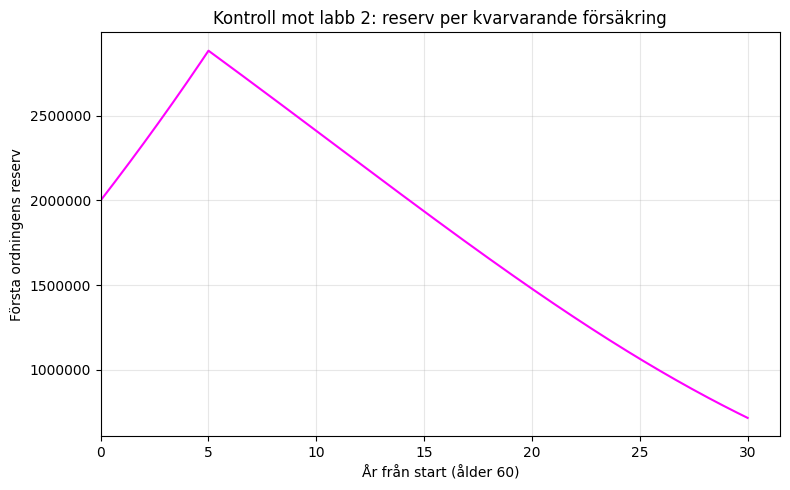

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.arange(len(G)) / 12, G, color="magenta")
ax.set(xlabel="År från start (ålder 60)", ylabel="Första ordningens reserv",
       title="Kontroll mot labb 2: reserv per kvarvarande försäkring")
ax.ticklabel_format(style="plain", axis="y")
ax.set_xlim(left=0)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Nästa steg: uppgift 1 – tillståndsmodellen

Implementera PP, PO, TR och DE i `state_model.py`. Därefter kan reserver och kassaflöden viktas med populationerna. De återstående modellfilerna är ännu tomma.